# ATAC Data Notebook

Repo-relative sanity check for the processed ATAC arrays. Use the benchmark CLI for full embedding sweeps.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ne_aligned_utils.methods import compute_pca_embedding_from_arrays

DATASET_DIR = Path('data/atac')
DATASET_DIR

PosixPath('data/atac')

In [2]:
x0 = np.load(DATASET_DIR / 'data1.npy')
x1 = np.load(DATASET_DIR / 'data2.npy')
metadata = pd.read_csv(DATASET_DIR / 'cells_metadata.csv')
label_names = tuple(sorted(metadata['cell_type'].astype(str).unique()))
label_to_code = {name: idx for idx, name in enumerate(label_names)}
labels_all = metadata['cell_type'].astype(str).map(label_to_code).to_numpy(dtype=int)
method = metadata['method'].astype(str).to_numpy()
labels0 = labels_all[method == 'data1']
labels1 = labels_all[method == 'data2']
if labels0.shape[0] != x0.shape[0] or labels1.shape[0] != x1.shape[0]:
    raise ValueError('ATAC metadata labels do not match data1/data2 row counts.')
pd.DataFrame({
    'batch': ['data1', 'data2'],
    'cells': [x0.shape[0], x1.shape[0]],
    'features': [x0.shape[1], x1.shape[1]],
    'labels': [np.unique(labels0).size, np.unique(labels1).size],
})

,batch,cells,features,labels
0,data1,3618,1000,6
1,data2,3750,1000,6


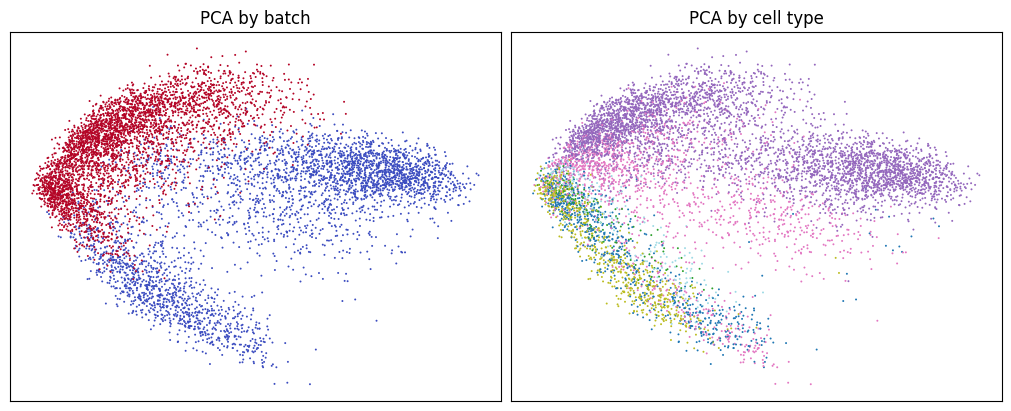

In [3]:
embedding = compute_pca_embedding_from_arrays(x0, x1, embd_dim=2, random_state=0)
batch_ids = np.concatenate([np.zeros(x0.shape[0], dtype=int), np.ones(x1.shape[0], dtype=int)])
labels = np.concatenate([labels0, labels1])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].scatter(embedding[:, 0], embedding[:, 1], c=batch_ids, s=2, cmap='coolwarm', linewidths=0)
axes[0].set_title('PCA by batch')
axes[1].scatter(embedding[:, 0], embedding[:, 1], c=labels, s=2, cmap='tab20', linewidths=0)
axes[1].set_title('PCA by cell type')
for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
plt.show()